In [1]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Titanic dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [2]:

# Display first 5 records
print("First 5 Records:")
display(df.head())

# Display last 5 records
print("Last 5 Records:")
display(df.tail())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display data types
print("Data Types:")
print(df.dtypes)


First 5 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last 5 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Dataset Shape: (891, 15)
Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object


In [3]:

# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

# Display summary statistics
print("\nSummary Statistics:")
display(df.describe())

# Display categorical data statistics
print("\nCategorical Statistics:")
display(df.describe(include='object'))


Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'deck', 'embark_town', 'alive']

Summary Statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Categorical Statistics:


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [4]:

# Count missing values
missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create a missing value summary
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

print("Missing Value Summary:")
display(missing_summary)


Missing Value Summary:


,Missing Values,Missing Percentage
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
age,177,19.865320
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000
embarked,2,0.224467
class,0,0.000000
who,0,0.000000


In [5]:

# Create a copy of original dataset
df_clean = df.copy()

# Remove deck column due to excessive missing values
df_clean = df_clean.drop(columns=['deck'])

# Fill missing Age values with median
df_clean['age'] = df_clean['age'].fillna(
    df_clean['age'].median()
)

# Fill missing Embarked values with mode
df_clean['embarked'] = df_clean['embarked'].fillna(
    df_clean['embarked'].mode()[0]
)

# Fill missing Embark_town values with mode
df_clean['embark_town'] = df_clean['embark_town'].fillna(
    df_clean['embark_town'].mode()[0]
)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:", df_clean.shape)


Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Cleaned Dataset Shape: (891, 14)


Duplicate Records: 116

Unique Sex Values:
['male' 'female']

Unique Embarked Values:
['S' 'C' 'Q']

Unique Embark Town Values:
['Southampton' 'Cherbourg' 'Queenstown']

Final Dataset Shape: (775, 14)


In [7]:

# Check duplicate records
print("Duplicate Records:", df_clean.duplicated().sum())

# Remove duplicate records if present
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from categorical columns
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

# Check unique values in important columns
print("\nUnique Sex Values:")
print(df_clean['sex'].unique())

print("\nUnique Embarked Values:")
print(df_clean['embarked'].unique())

print("\nUnique Embark Town Values:")
print(df_clean['embark_town'].unique())

print("\nFinal Dataset Shape:", df_clean.shape)


Duplicate Records: 0

Unique Sex Values:
['male' 'female']

Unique Embarked Values:
['S' 'C' 'Q']

Unique Embark Town Values:
['Southampton' 'Cherbourg' 'Queenstown']

Final Dataset Shape: (775, 14)


In [8]:

# Summary statistics
print("Numerical Summary:")
display(df_clean.describe())

# Frequency count of passenger gender
print("\nPassenger Gender Count:")
display(df_clean['sex'].value_counts())

# Frequency count of survival
print("\nSurvival Count:")
display(df_clean['survived'].value_counts())


Numerical Summary:


,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Passenger Gender Count:


,count
sex,
male,483
female,292



Survival Count:


,count
survived,
0,455
1,320


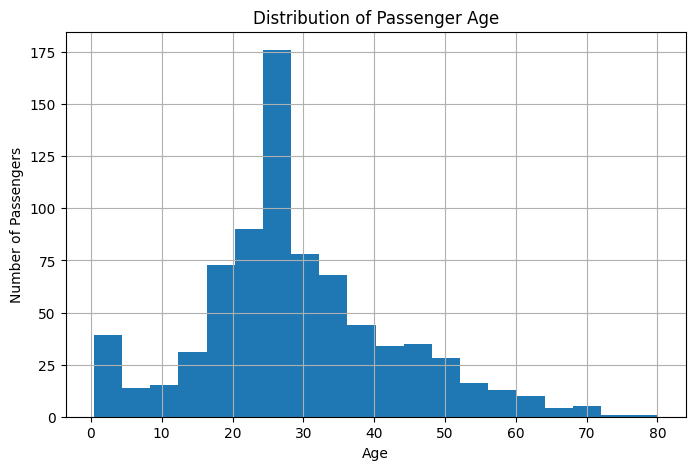

In [9]:

plt.figure(figsize=(8, 5))

plt.hist(df_clean['age'], bins=20)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.grid(True)
plt.show()


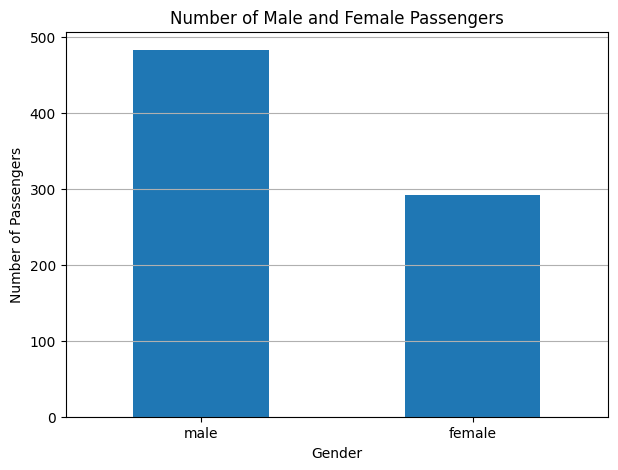

In [10]:

plt.figure(figsize=(7, 5))

df_clean['sex'].value_counts().plot(kind='bar')

plt.title("Number of Male and Female Passengers")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


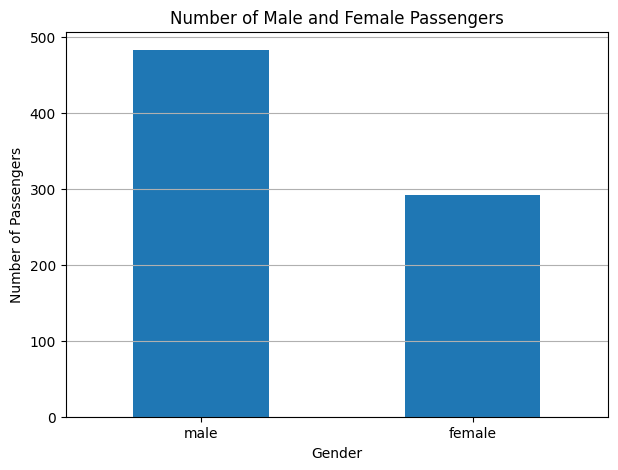

In [11]:

plt.figure(figsize=(7, 5))

df_clean['sex'].value_counts().plot(kind='bar')

plt.title("Number of Male and Female Passengers")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


In [14]:

# Identify categorical columns
categorical_cols = df_clean.select_dtypes(
    include=['object', 'bool']
).columns

print("Categorical Columns:")
print(list(categorical_cols))

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("\nDataset After Encoding:")
display(df_encoded.head())

print("Shape Before Encoding:", df_clean.shape)
print("Shape After Encoding:", df_encoded.shape)


Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']

Dataset After Encoding:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,adult_male_True,embark_town_Queenstown,embark_town_Southampton,alive_yes,alone_True
0,0,3,22.0,1,0,7.2500,1,0,1,0,1,1,0,1,0,1,0,0
1,1,1,38.0,1,0,71.2833,0,0,0,0,0,0,1,0,0,0,1,0
2,1,3,26.0,0,0,7.9250,0,0,1,0,1,0,1,0,0,1,1,1
3,1,1,35.0,1,0,53.1000,0,0,1,0,0,0,1,0,0,1,1,0
4,0,3,35.0,0,0,8.0500,1,0,1,0,1,1,0,1,0,1,0,1


Shape Before Encoding: (775, 14)
Shape After Encoding: (775, 18)


In [15]:

from sklearn.preprocessing import StandardScaler

# Select numerical input features
scale_columns = ['age', 'sibsp', 'parch', 'fare']

# Create StandardScaler
scaler = StandardScaler()

# Apply scaling
df_encoded[scale_columns] = scaler.fit_transform(
    df_encoded[scale_columns]
)

print("Dataset After Scaling:")
display(df_encoded.head())

print("\nScaled Feature Statistics:")
display(df_encoded[scale_columns].describe())


Dataset After Scaling:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,adult_male_True,embark_town_Queenstown,embark_town_Southampton,alive_yes,alone_True
0,0,3,-0.551060,0.475876,-0.500754,-0.527515,1,0,1,0,1,1,0,1,0,1,0,0
1,1,1,0.611945,0.475876,-0.500754,0.695086,0,0,0,0,0,0,1,0,0,0,1,0
2,1,3,-0.260308,-0.534545,-0.500754,-0.514627,0,0,1,0,1,0,1,0,0,1,1,1
3,1,1,0.393881,0.475876,-0.500754,0.347909,0,0,1,0,0,0,1,0,0,1,1,0
4,0,3,0.393881,-0.534545,-0.500754,-0.512240,1,0,1,0,1,1,0,1,0,1,0,1



Scaled Feature Statistics:


,age,sibsp,parch,fare
count,7.750000e+02,7.750000e+02,7.750000e+02,7.750000e+02
mean,2.521281e-16,-3.208903e-17,1.375244e-17,-1.134576e-16
std,1.000646e+00,1.000646e+00,1.000646e+00,1.000646e+00
min,-2.119661e+00,-5.345452e-01,-5.007545e-01,-6.659405e-01
25%,-6.237473e-01,-5.345452e-01,-5.007545e-01,-5.122402e-01
50%,-1.149330e-01,-5.345452e-01,-5.007545e-01,-3.623586e-01
75%,4.665691e-01,4.758756e-01,6.896894e-01,-1.299298e-02
max,3.664831e+00,7.548821e+00,6.641909e+00,9.116066e+00


In [16]:

# Check final dataset
print("Final Dataset Shape:", df_encoded.shape)

# Check missing values
print("\nTotal Missing Values:")
print(df_encoded.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df_encoded.duplicated().sum())

# Display first 5 records
print("\nFinal Prepared Dataset:")
display(df_encoded.head())

# Save dataset
df_encoded.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("\nDataset saved successfully!")


Final Dataset Shape: (775, 18)

Total Missing Values:
0

Duplicate Records:
0

Final Prepared Dataset:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,adult_male_True,embark_town_Queenstown,embark_town_Southampton,alive_yes,alone_True
0,0,3,-0.551060,0.475876,-0.500754,-0.527515,1,0,1,0,1,1,0,1,0,1,0,0
1,1,1,0.611945,0.475876,-0.500754,0.695086,0,0,0,0,0,0,1,0,0,0,1,0
2,1,3,-0.260308,-0.534545,-0.500754,-0.514627,0,0,1,0,1,0,1,0,0,1,1,1
3,1,1,0.393881,0.475876,-0.500754,0.347909,0,0,1,0,0,0,1,0,0,1,1,0
4,0,3,0.393881,-0.534545,-0.500754,-0.512240,1,0,1,0,1,1,0,1,0,1,0,1



Dataset saved successfully!


In [17]:

from google.colab import files

files.download('Titanic_Prepared_Dataset.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>